In [69]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("tesla.csv")
df = df.fillna(0)
df['Date'] = pd.to_datetime(df['Date'])
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800000,5.000000,3.508000,4.778000,4.778000,93831500
1,2010-06-30,5.158000,6.084000,4.660000,4.766000,4.766000,85935500
2,2010-07-01,5.000000,5.184000,4.054000,4.392000,4.392000,41094000
3,2010-07-02,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
4,2010-07-06,4.000000,4.000000,3.166000,3.222000,3.222000,34334500
...,...,...,...,...,...,...,...
2951,2022-03-18,874.489990,907.849976,867.390015,905.390015,905.390015,33408500
2952,2022-03-21,914.979980,942.849976,907.090027,921.159973,921.159973,27327200
2953,2022-03-22,930.000000,997.859985,921.750000,993.979980,993.979980,35289500
2954,2022-03-23,979.940002,1040.699951,976.400024,999.109985,999.109985,40225400


In [70]:
df = df.set_index('Date')
df = df.resample('D').ffill()
df

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-06-29,3.800000,5.000000,3.508000,4.778000,4.778000,93831500
2010-06-30,5.158000,6.084000,4.660000,4.766000,4.766000,85935500
2010-07-01,5.000000,5.184000,4.054000,4.392000,4.392000,41094000
2010-07-02,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
2010-07-03,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
...,...,...,...,...,...,...
2022-03-20,874.489990,907.849976,867.390015,905.390015,905.390015,33408500
2022-03-21,914.979980,942.849976,907.090027,921.159973,921.159973,27327200
2022-03-22,930.000000,997.859985,921.750000,993.979980,993.979980,35289500


In [71]:
group_data = df[["Low", "High"]]
group_data.head()

,Low,High
Date,,
2010-06-29,3.508,5.000
2010-06-30,4.660,6.084
2010-07-01,4.054,5.184
2010-07-02,3.742,4.620
2010-07-03,3.742,4.620


In [72]:
len_train = int(len(group_data) * 0.8)
train = group_data[:len_train]
test = group_data[len_train:]

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            3     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  9.13476D-01    |proj g|=  1.70089D-01

At iterate    5    f=  9.04051D-01    |proj g|=  2.96600D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    3      8     11      1     0     0   1.108D-06   9.040D-01
  F =  0.90404874663550139     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            


 This problem is unconstrained.


<Axes: xlabel='Date'>

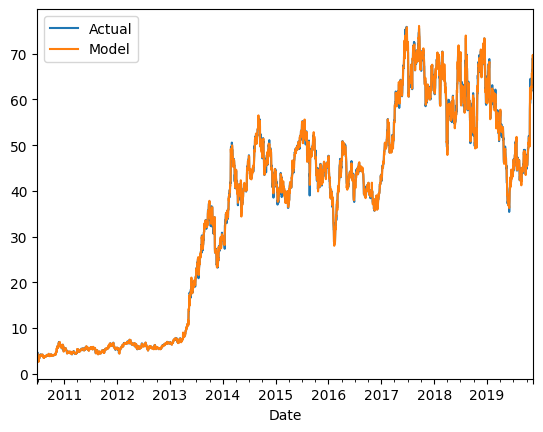

In [73]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima

auto = auto_arima(
    train["Low"],
    exogenous=train['High'],  
    seasonal=True,              
    m=52,                        
    trace=False,
    suppress_warnings=True,
    error_action="ignore",
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['Low'],
    exog=train['High'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

predictions = model_fit.predict(start=0, end=len(train) - 1, exog=train["Low"])

train["Low"].plot(label = "Actual", legend = True)
predictions.plot(label = "Model", legend = True)

<Axes: xlabel='Date'>

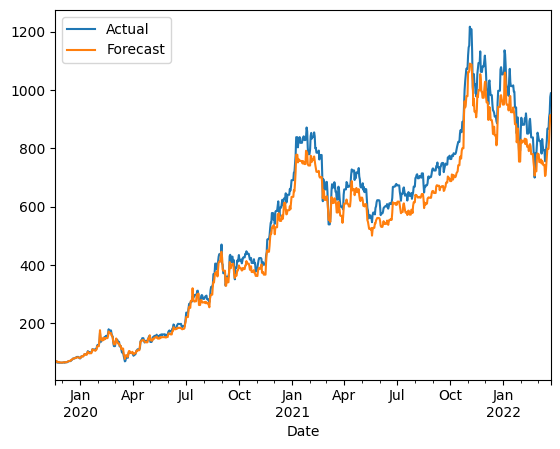

In [74]:
forecast = model_fit.forecast(steps = len(test), exog = test["High"])
test["Low"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

In [75]:
from sklearn.metrics import mean_absolute_error

# Mean Absolute Error (MAE)
mae = mean_absolute_error(test["Low"], forecast)
print(f"Mean Absolute Error (MAE): {mae}")

Mean Absolute Error (MAE): 39.54022992062622


In [76]:
from sklearn.metrics import mean_squared_error

# Mean Squared Error (MSE)
mse = mean_squared_error(test["Low"], forecast)
print(f"Mean Squared Error (MSE): {mse}")

Mean Squared Error (MSE): 2436.1331853293145


In [77]:
import numpy as np

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mean_squared_error(test["Low"], forecast))
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 49.357199934045234


In [78]:
# Mean Absolute Percentage Error (MAPE)
test.loc[:, "Kesalahan"] = np.abs(test["Low"] - forecast)
mape = np.mean(test["Kesalahan"] / test["Low"]) * 100
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Absolute Percentage Error (MAPE): 6.36%


/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_11924/1037575105.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.loc[:, "Kesalahan"] = np.abs(test["Low"] - forecast)
